# Notebook 07: Subgroups, recording systems and ranking stability on 2025

**Study:** predicting recorded road casualty severity (KSI) in Great Britain. This notebook carries out the pre-specified checks in section 3.7.5 that use only the frozen 2025 scores. **It refits nothing.** Models, settings and thresholds stay exactly as frozen in notebook 05.

**What it does**
1. Checks the frozen scores, the labels and the evaluation code against the checksums recorded by notebooks 05 and 06.
2. Reports performance at the **fixed thresholds** for pedestrians, cyclists, motorcyclists and e-scooter riders (and the remaining casualty types, shown for completeness), and for the three recording-system groups. Each group gets its number of records, KSI cases, KSI prevalence and 95% intervals. Groups with fewer than 30 KSI cases are flagged.
3. Repeats the 2025 test on the **unchanged forces** only (forces whose recording system did not change across 2023 to 2025) and compares it with the full set, using the same bootstrap draws.
4. Splits the rise in KSI share between 2023-24 and 2025 into a part inside each group and a part due to a change in group mix.
5. Checks whether the **ranking of the nine model and training combinations** is stable across training treatments, thresholds and bootstrap draws, using the draws saved by notebook 06.
6. Compares **recorded and DfT-adjusted KSI rates** in annual summaries.

Score-based subgroup measures (average precision, ROC-AUC, Brier score, calibration) are computed for the three untreated fits. Decision measures are computed for all nine combinations at both thresholds. The bootstrap resamples whole collisions with replacement, 2,000 times, and every group and model sees the same draws.

**To run it:** run all cells in order. Notebook 06 must have been run first.

In [1]:
# 1. Setup and checks ---------------------------------------------------------------------------
import os, sys, json, hashlib, subprocess, time, sqlite3, datetime as dt
from pathlib import Path
import numpy as np
import pandas as pd
import sklearn
import matplotlib
import matplotlib.pyplot as plt
from scipy.stats import rankdata, spearmanr, kendalltau
try:
    display
except NameError:
    display = print

BOOT_REPS = 2000          # paired collision bootstrap replicates, as in Chapter 3

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/stats19_severity')
else:
    PROJECT = Path(os.environ.get('PROJECT_DIR', './stats19_severity'))
CODE = PROJECT / 'code'; MOD = PROJECT / 'outputs' / 'models'; FINAL = MOD / 'final'; SEARCH = MOD / 'search'
RES = PROJECT / 'outputs' / 'results'; ENV = PROJECT / 'environment'; SEALED = PROJECT / 'data' / 'sealed_2025_labels'
DATA = PROJECT / 'data' / 'model_inputs'
SEED = 20261107
BOOT_SEED = SEED + 3        # notebook 06 used SEED + 2
def sha(path): return hashlib.sha256(Path(path).read_bytes()).hexdigest()
(ENV / 'pip_freeze_notebook07.txt').write_text(subprocess.run([sys.executable, '-m', 'pip', 'freeze'], capture_output=True, text=True).stdout)

assert (FINAL / 'unseal_log.json').exists() and (RES / 'results_2025_summary.json').exists(), 'Run notebook 06 first.'
rec = json.loads((FINAL / 'freeze_record.json').read_text())
s06 = json.loads((RES / 'results_2025_summary.json').read_text())
sys.path.insert(0, str(CODE))
import importlib, stats19_eval
importlib.reload(stats19_eval)
from stats19_eval import *
assert sha(CODE / 'stats19_eval.py') == s06['eval_module_sha256'], 'The evaluation code changed since notebook 06.'
score_file = FINAL / rec['scores_2025']['file']
assert sha(score_file) == rec['scores_2025']['sha256'], 'The saved 2025 scores differ from the frozen file.'
labels_path = SEALED / 'labels_test_2025_SEALED.csv'
assert sha(labels_path) == s06['labels_sha256'], 'The labels differ from the file opened in notebook 06.'
print('scikit-learn', sklearn.__version__, '| frozen scores, labels and evaluation code match their recorded checksums.')
print('Eval module sha256', sha(CODE / 'stats19_eval.py')[:16], '| bootstrap seed', BOOT_SEED, '| replicates', BOOT_REPS)

Mounted at /content/drive
scikit-learn 1.6.1 | frozen scores, labels and evaluation code match their recorded checksums.
Eval module sha256 f3418de16c7259ff | bootstrap seed 20261110 | replicates 2000


In [2]:
# 2. Join scores, labels and strata ---------------------------------------------------------------
scores = pd.read_parquet(score_file) if score_file.suffix == '.parquet' else pd.read_pickle(score_file)
labels = pd.read_csv(labels_path)
strata25 = pd.read_csv(DATA / 'eval_strata_2025.csv')
df = scores.merge(labels, on='cas_key', how='left', validate='one_to_one').merge(strata25, on='cas_key', how='left', validate='one_to_one')
assert df['ksi'].notna().all() and df['system_group'].notna().all() and df['road_user_group'].notna().all(), 'Missing labels or strata for some casualties.'
df['ksi'] = df['ksi'].astype(int)
df['coll'] = df['cas_key'].str.split('|').str[0]
coll_codes, coll_index = pd.factorize(df['coll'])
n_coll = len(coll_index)
y = df['ksi'].values
KINDS, TREATMENTS = ['lr', 'rf', 'hgb'], ['untreated', 'weight', 'oversample']
COMBOS = [(k, t) for k in KINDS for t in TREATMENTS]
UNT = [(k, 'untreated') for k in KINDS]
THR = rec['thresholds']
RULES = ['ref', 'opt']
DEC = [(k, t, r) for (k, t) in COMBOS for r in RULES]
for k, t in COMBOS:
    p = df[f'{k}__{t}'].values
    assert ((p >= THR[f'{k}__{t}']['opt']).astype(int) == df[f'{k}__{t}__opt'].values).all()
P = {c: df[f'{c[0]}__{c[1]}'].values.astype(float) for c in COMBOS}
X = {c: clip_logit(P[c]) for c in COMBOS}
FLAGS = {d: df[f'{d[0]}__{d[1]}__{d[2]}'].values for d in DEC}
if len(df) == 127883:
    assert y.sum() == 29296, 'The 2025 KSI count does not match Table 3.2.'
print(f'2025 casualties {len(df)} | collisions {n_coll} | KSI {y.sum()} ({y.mean():.4f})')

ROAD = ['pedestrian', 'cyclist', 'motorcyclist', 'e-scooter rider', 'other']
SYS = ['stable injury-based', 'stable non-injury-based', 'changed or mixed']
assert set(df['road_user_group']) <= set(ROAD) and set(df['system_group']) <= set(SYS), 'Unexpected group labels.'
GROUPS = {'All casualties': np.ones(len(df), bool)}
for r in ROAD: GROUPS[f'Road user: {r}'] = (df['road_user_group'] == r).values
for s in SYS: GROUPS[f'Recording system: {s}'] = (df['system_group'] == s).values
UNCH = 'Unchanged forces (both stable groups)'
GROUPS[UNCH] = df['system_group'].isin(['stable injury-based', 'stable non-injury-based']).values
ALL = 'All casualties'
print(pd.DataFrame({'casualties': {g: int(m.sum()) for g, m in GROUPS.items()}, 'KSI cases': {g: int(y[m].sum()) for g, m in GROUPS.items()}}))

2025 casualties 127883 | collisions 101525 | KSI 29296 (0.2291)
                                           casualties  KSI cases
All casualties                                 127883      29296
Road user: pedestrian                           19978       6195
Road user: cyclist                              16042       4303
Road user: motorcyclist                         15447       6002
Road user: e-scooter rider                       1227        442
Road user: other                                75189      12354
Recording system: stable injury-based           70735      17440
Recording system: stable non-injury-based        8082       1807
Recording system: changed or mixed              49066      10049
Unchanged forces (both stable groups)           78817      19247


In [3]:
# 3. Subgroup performance at the frozen thresholds, with the paired collision bootstrap -------------------
SCORE_KEYS = ['ap', 'auc', 'brier', 'cal_intercept', 'cal_slope']
DEC_KEYS = ['recall', 'precision', 'specificity', 'balanced_accuracy', 'macro_f1', 'flagged_share']
NAN_SCORES = {k: np.nan for k in SCORE_KEYS}

def safe_scores(prep, x, p, yy, w, start=(0.0, 1.0)):
    pos, neg = (w * yy).sum(), (w * (1 - yy)).sum()
    if pos <= 0 or neg <= 0: return dict(NAN_SCORES), start
    try:
        with np.errstate(all='ignore'):
            m, warm = score_metrics(prep, x, p, yy, w, start=start)
    except (np.linalg.LinAlgError, FloatingPointError, ZeroDivisionError):
        return dict(NAN_SCORES), start
    m = {k: (v if np.isfinite(v) else np.nan) for k, v in m.items()}
    return m, (warm if all(np.isfinite(warm)) else start)

G = {}
for name, mask in GROUPS.items():
    idx = np.flatnonzero(mask); yy = y[idx].astype(float); codes = coll_codes[idx]
    g = dict(idx=idx, y=yy, codes=codes,
             ycnt=np.bincount(codes, weights=yy, minlength=n_coll), ncnt=np.bincount(codes, minlength=n_coll).astype(float),
             pcnt={c: np.bincount(codes, weights=P[c][idx], minlength=n_coll) for c in UNT},
             prep={c: RankPrep(P[c][idx], yy) for c in UNT}, x={c: X[c][idx] for c in UNT}, p={c: P[c][idx] for c in UNT},
             cc=np.stack([collision_counts(codes, n_coll, FLAGS[d][idx], yy) for d in DEC], axis=1).reshape(n_coll, -1))
    G[name] = g

POINT, WARM = {}, {}
ones_cache = {}
for name, g in G.items():
    n = len(g['idx']); one = np.ones(n)
    POINT[f'{name}|prevalence'] = g['y'].mean()
    for c in UNT:
        m, WARM[(name, c)] = safe_scores(g['prep'][c], g['x'][c], g['p'][c], g['y'], one)
        for k in SCORE_KEYS: POINT[f'{name}|{c[0]}__{c[1]}|{k}'] = m[k]
        POINT[f'{name}|{c[0]}__{c[1]}|mean_pred'] = g['p'][c].mean()
        POINT[f'{name}|{c[0]}__{c[1]}|ap_lift'] = m['ap'] / POINT[f'{name}|prevalence'] if POINT[f'{name}|prevalence'] > 0 else np.nan
    with np.errstate(all='ignore'):
        r = decision_rates(g['cc'].sum(axis=0).reshape(len(DEC), 4))
    for j, d in enumerate(DEC):
        for k in DEC_KEYS: POINT[f'{name}|{d[0]}__{d[1]}__{d[2]}|{k}'] = float(r[k][j])

rng = np.random.RandomState(BOOT_SEED)
draws = {k: np.full(BOOT_REPS, np.nan) for k in POINT}
t0 = time.time()
for b in range(BOOT_REPS):
    wc = rng.multinomial(n_coll, np.full(n_coll, 1.0 / n_coll)).astype(float)
    for name, g in G.items():
        den = wc @ g['ncnt']
        if den <= 0: continue
        prev = (wc @ g['ycnt']) / den
        draws[f'{name}|prevalence'][b] = prev
        w = wc[g['codes']]
        for c in UNT:
            m, _ = safe_scores(g['prep'][c], g['x'][c], g['p'][c], g['y'], w, start=WARM[(name, c)])
            for k in SCORE_KEYS: draws[f'{name}|{c[0]}__{c[1]}|{k}'][b] = m[k]
            draws[f'{name}|{c[0]}__{c[1]}|mean_pred'][b] = (wc @ g['pcnt'][c]) / den
            draws[f'{name}|{c[0]}__{c[1]}|ap_lift'][b] = m['ap'] / prev if prev > 0 else np.nan
        with np.errstate(all='ignore'):
            r = decision_rates((wc @ g['cc']).reshape(len(DEC), 4))
        for j, d in enumerate(DEC):
            for k in DEC_KEYS: draws[f'{name}|{d[0]}__{d[1]}__{d[2]}|{k}'][b] = r[k][j]
    if (b + 1) % 250 == 0:
        print(f'  {b + 1}/{BOOT_REPS} replicates | {(time.time() - t0) / 60:.1f} min')
boot_sub = pd.DataFrame(draws)
boot_sub.to_parquet(RES / 'bootstrap_draws_subgroups_2025.parquet', index=False)
print('Bootstrap finished in', round((time.time() - t0) / 60, 1), 'min. Seed', BOOT_SEED)

def interval(key):
    v = boot_sub[key].values; v = v[np.isfinite(v)]
    return (np.percentile(v, [2.5, 97.5]) if len(v) >= 0.95 * BOOT_REPS else np.array([np.nan, np.nan])), len(v)

  250/2000 replicates | 2.8 min
  500/2000 replicates | 5.6 min
  750/2000 replicates | 8.3 min
  1000/2000 replicates | 11.0 min
  1250/2000 replicates | 13.8 min
  1500/2000 replicates | 16.6 min
  1750/2000 replicates | 19.3 min
  2000/2000 replicates | 22.0 min
Bootstrap finished in 22.0 min. Seed 20261110


In [4]:
# 4. Tables: overview, score measures, decision measures ---------------------------------------------------
fmt = lambda e, lo, hi, d=3: f'{e:.{d}f} [{lo:.{d}f}, {hi:.{d}f}]' if np.isfinite(e) and np.isfinite(lo) else 'not estimable'
ov = []
for name, g in G.items():
    (lo, hi), nv = interval(f'{name}|prevalence')
    nk = int(g['y'].sum())
    ov.append(dict(group=name, casualties=len(g['idx']), collisions=int((g['ncnt'] > 0).sum()), ksi_cases=nk, prevalence=POINT[f'{name}|prevalence'], prev_lo=lo, prev_hi=hi, fewer_than_30_ksi=nk < 30))
ov = pd.DataFrame(ov)
ov.round(5).to_csv(RES / 'subgroups_2025_overview.csv', index=False)
show = ov.copy(); show['prevalence'] = [fmt(a, b, c) for a, b, c in zip(ov.prevalence, ov.prev_lo, ov.prev_hi)]
print('Group sizes and KSI prevalence in 2025:'); display(show[['group', 'casualties', 'collisions', 'ksi_cases', 'prevalence', 'fewer_than_30_ksi']])

rows = []
for name in G:
    for c in UNT:
        for k in SCORE_KEYS + ['mean_pred', 'ap_lift']:
            key = f'{name}|{c[0]}__{c[1]}|{k}'; (lo, hi), nv = interval(key)
            rows.append(dict(group=name, model=c[0], training=c[1], measure=k, estimate=POINT[key], lo=lo, hi=hi, valid_draws=nv))
sub_scores = pd.DataFrame(rows)
sub_scores.round(5).to_csv(RES / 'subgroups_2025_score_measures.csv', index=False)
w_ = sub_scores[sub_scores.measure.isin(['ap', 'auc', 'cal_intercept', 'cal_slope'])].copy()
w_['txt'] = [fmt(a, b, c) for a, b, c in zip(w_.estimate, w_.lo, w_.hi)]
print('\nScore-based measures by group, untreated fits (estimate [95% interval]):')
display(w_.pivot(index=['group', 'model'], columns='measure', values='txt')[['ap', 'auc', 'cal_intercept', 'cal_slope']].loc[[(g, k) for g in G for k in KINDS]])

rows = []
for j, d in enumerate(DEC):
    for name, g in G.items():
        cnt = g['cc'].sum(axis=0).reshape(len(DEC), 4)[j]
        base = dict(group=name, model=d[0], training=d[1], rule=d[2], threshold=THR[f'{d[0]}__{d[1]}'][d[2]], tp=int(cnt[0]), fp=int(cnt[1]), fn=int(cnt[2]), tn=int(cnt[3]))
        for k in DEC_KEYS:
            key = f'{name}|{d[0]}__{d[1]}__{d[2]}|{k}'; (lo, hi), nv = interval(key)
            base.update({k: POINT[key], k + '_lo': lo, k + '_hi': hi})
        rows.append(base)
sub_dec = pd.DataFrame(rows)
sub_dec.round(5).to_csv(RES / 'subgroups_2025_decision_measures.csv', index=False)
sd = sub_dec[(sub_dec.model == 'hgb') & (sub_dec.training == 'untreated') & (sub_dec.rule == 'opt')].copy()
for k in ['recall', 'precision', 'specificity', 'macro_f1', 'flagged_share']:
    sd[k] = [fmt(a, b, c) for a, b, c in zip(sd[k], sd[k + '_lo'], sd[k + '_hi'])]
print('\nSelected model (hgb, untreated) at the frozen macro-F1 threshold, by group:')
display(sd[['group', 'threshold', 'tp', 'fp', 'fn', 'tn', 'recall', 'precision', 'specificity', 'macro_f1', 'flagged_share']])
print('Precision, flagged share and macro-F1 depend on each group\'s KSI prevalence, so they are not comparable across groups on their own.')

Group sizes and KSI prevalence in 2025:


,group,casualties,collisions,ksi_cases,prevalence,fewer_than_30_ksi
0,All casualties,127883,101525,29296,"0.229 [0.227, 0.232]",False
1,Road user: pedestrian,19978,19115,6195,"0.310 [0.303, 0.317]",False
2,Road user: cyclist,16042,15836,4303,"0.268 [0.261, 0.275]",False
3,Road user: motorcyclist,15447,14959,6002,"0.389 [0.381, 0.397]",False
4,Road user: e-scooter rider,1227,1168,442,"0.360 [0.332, 0.387]",False
5,Road user: other,75189,51609,12354,"0.164 [0.161, 0.167]",False
6,Recording system: stable injury-based,70735,54547,17440,"0.247 [0.243, 0.250]",False
7,Recording system: stable non-injury-based,8082,6229,1807,"0.224 [0.214, 0.233]",False
8,Recording system: changed or mixed,49066,40749,10049,"0.205 [0.201, 0.209]",False
9,Unchanged forces (both stable groups),78817,60776,19247,"0.244 [0.241, 0.248]",False



Score-based measures by group, untreated fits (estimate [95% interval]):


measure                                                            ap  \
group                                     model                         
All casualties                            lr     0.442 [0.432, 0.450]   
                                          rf     0.459 [0.453, 0.465]   
                                          hgb    0.466 [0.460, 0.472]   
Road user: pedestrian                     lr     0.481 [0.447, 0.509]   
                                          rf     0.521 [0.508, 0.534]   
                                          hgb    0.527 [0.514, 0.540]   
Road user: cyclist                        lr     0.395 [0.381, 0.410]   
                                          rf     0.418 [0.402, 0.433]   
                                          hgb    0.421 [0.406, 0.436]   
Road user: motorcyclist                   lr     0.603 [0.589, 0.617]   
                                          rf     0.611 [0.598, 0.625]   
                                          hgb    0.620 [0.606, 0.633]   
Road user: e-scooter rider                lr     0.485 [0.436, 0.535]   
                                          rf     0.488 [0.443, 0.538]   
                                          hgb    0.501 [0.453, 0.552]   
Road user: other                          lr     0.301 [0.293, 0.310]   
                                          rf     0.315 [0.306, 0.324]   
                                          hgb    0.321 [0.312, 0.330]   
Recording system: stable injury-based     lr     0.458 [0.450, 0.466]   
                                          rf     0.472 [0.464, 0.480]   
                                          hgb    0.479 [0.471, 0.487]   
Recording system: stable non-injury-based lr     0.430 [0.375, 0.486]   
                                          rf     0.467 [0.442, 0.494]   
                                          hgb    0.474 [0.450, 0.501]   
Recording system: changed or mixed        lr     0.418 [0.408, 0.429]   
                                          rf     0.437 [0.427, 0.447]   
                                          hgb    0.441 [0.431, 0.452]   
Unchanged forces (both stable groups)     lr     0.454 [0.441, 0.465]   
                                          rf     0.471 [0.463, 0.479]   
                                          hgb    0.478 [0.471, 0.486]   

measure                                                           auc  \
group                                     model                         
All casualties                            lr     0.724 [0.720, 0.727]   
                                          rf     0.733 [0.730, 0.737]   
                                          hgb    0.738 [0.734, 0.741]   
Road user: pedestrian                     lr     0.678 [0.666, 0.689]   
                                          rf     0.705 [0.698, 0.712]   
                                          hgb    0.708 [0.700, 0.716]   
Road user: cyclist                        lr     0.641 [0.631, 0.650]   
                                          rf     0.657 [0.647, 0.667]   
                                          hgb    0.657 [0.647, 0.666]   
Road user: motorcyclist                   lr     0.729 [0.721, 0.737]   
                                          rf     0.734 [0.726, 0.742]   
                                          hgb    0.740 [0.733, 0.748]   
Road user: e-scooter rider                lr     0.633 [0.600, 0.665]   
                                          rf     0.637 [0.603, 0.669]   
                                          hgb    0.650 [0.617, 0.682]   
Road user: other                          lr     0.695 [0.690, 0.701]   
                                          rf     0.703 [0.697, 0.708]   
                                          hgb    0.709 [0.703, 0.714]   
Recording system: stable injury-based     lr     0.713 [0.709, 0.718]   
                                          rf     0.723 [0.718, 0.727]   
                                          hgb    0.727 [0


Selected model (hgb, untreated) at the frozen macro-F1 threshold, by group:


,group,threshold,tp,fp,fn,tn,recall,precision,specificity,macro_f1,flagged_share
130,All casualties,0.3,14597,18314,14699,80273,"0.498 [0.492, 0.504]","0.444 [0.438, 0.449]","0.814 [0.812, 0.817]","0.649 [0.646, 0.652]","0.257 [0.255, 0.260]"
131,Road user: pedestrian,0.3,4351,5519,1844,8264,"0.702 [0.690, 0.714]","0.441 [0.431, 0.451]","0.600 [0.591, 0.608]","0.617 [0.610, 0.623]","0.494 [0.486, 0.502]"
132,Road user: cyclist,0.3,1892,2842,2411,8897,"0.440 [0.425, 0.454]","0.400 [0.385, 0.413]","0.758 [0.750, 0.766]","0.595 [0.587, 0.603]","0.295 [0.288, 0.302]"
133,Road user: motorcyclist,0.3,5006,4694,996,4751,"0.834 [0.824, 0.844]","0.516 [0.506, 0.527]","0.503 [0.493, 0.513]","0.632 [0.624, 0.639]","0.628 [0.621, 0.636]"
134,Road user: e-scooter rider,0.3,258,303,184,482,"0.584 [0.534, 0.629]","0.460 [0.418, 0.502]","0.614 [0.580, 0.648]","0.589 [0.559, 0.618]","0.457 [0.428, 0.486]"
135,Road user: other,0.3,3090,4956,9264,57879,"0.250 [0.241, 0.259]","0.384 [0.372, 0.396]","0.921 [0.919, 0.924]","0.597 [0.592, 0.602]","0.107 [0.104, 0.110]"
136,Recording system: stable injury-based,0.3,8876,10648,8564,42647,"0.509 [0.501, 0.517]","0.455 [0.447, 0.462]","0.800 [0.796, 0.804]","0.648 [0.644, 0.652]","0.276 [0.272, 0.280]"
137,Recording system: stable non-injury-based,0.3,968,1293,839,4982,"0.536 [0.510, 0.560]","0.428 [0.407, 0.450]","0.794 [0.783, 0.805]","0.650 [0.637, 0.662]","0.280 [0.269, 0.291]"
138,Recording system: changed or mixed,0.3,4753,6373,5296,32644,"0.473 [0.462, 0.483]","0.427 [0.418, 0.437]","0.837 [0.833, 0.841]","0.649 [0.643, 0.654]","0.227 [0.223, 0.231]"
139,Unchanged forces (both stable groups),0.3,9844,11941,9403,47629,"0.511 [0.504, 0.519]","0.452 [0.445, 0.459]","0.800 [0.796, 0.803]","0.648 [0.645, 0.652]","0.276 [0.273, 0.280]"


Precision, flagged share and macro-F1 depend on each group's KSI prevalence, so they are not comparable across groups on their own.


In [5]:
# 5. Paired contrasts between groups (same draws) --------------------------------------------------------------
def diff(ga, gb, tail):
    ka, kb = f'{ga}|{tail}', f'{gb}|{tail}'
    d = boot_sub[ka].values - boot_sub[kb].values; d = d[np.isfinite(d)]
    lo, hi = np.percentile(d, [2.5, 97.5]) if len(d) >= 0.95 * BOOT_REPS else (np.nan, np.nan)
    return dict(group_a=ga, group_b=gb, measure=tail, difference=POINT[ka] - POINT[kb], lo=lo, hi=hi,
                interval_excludes_zero=bool(np.isfinite(lo) and (lo > 0 or hi < 0)))
PAIRS = [(UNCH, ALL), ('Recording system: stable injury-based', 'Recording system: stable non-injury-based'),
         ('Recording system: stable injury-based', 'Recording system: changed or mixed'),
         ('Recording system: stable non-injury-based', 'Recording system: changed or mixed')]
cons = []
for ga, gb in PAIRS:
    cons.append(diff(ga, gb, 'prevalence'))
    for c in UNT:
        m = f'{c[0]}__{c[1]}'
        for k in ('ap', 'auc', 'cal_intercept', 'mean_pred'): cons.append(diff(ga, gb, f'{m}|{k}'))
        for k in ('recall', 'precision', 'macro_f1', 'flagged_share'): cons.append(diff(ga, gb, f'{m}__opt|{k}'))
cons = pd.DataFrame(cons)
cons.round(5).to_csv(RES / 'subgroups_2025_paired_contrasts.csv', index=False)
print('Differences between groups (first minus second), 95% interval from the same collision draws.')
print('Unchanged-forces rows compare a subset with the full set, so they overlap and are not independent groups.')
display(cons[cons.measure.isin(['prevalence', 'hgb__untreated|ap', 'hgb__untreated|auc', 'hgb__untreated|cal_intercept', 'hgb__untreated__opt|recall', 'hgb__untreated__opt|macro_f1'])].round(4))

Differences between groups (first minus second), 95% interval from the same collision draws.
Unchanged-forces rows compare a subset with the full set, so they overlap and are not independent groups.


,group_a,group_b,measure,difference,lo,hi,interval_excludes_zero
0,Unchanged forces (both stable groups),All casualties,prevalence,0.0151,0.0133,0.0171,True
17,Unchanged forces (both stable groups),All casualties,hgb__untreated|ap,0.0124,0.0084,0.0168,True
18,Unchanged forces (both stable groups),All casualties,hgb__untreated|auc,-0.0085,-0.0110,-0.0059,True
19,Unchanged forces (both stable groups),All casualties,hgb__untreated|cal_intercept,0.0264,0.0159,0.0374,True
21,Unchanged forces (both stable groups),All casualties,hgb__untreated__opt|recall,0.0132,0.0088,0.0178,True
23,Unchanged forces (both stable groups),All casualties,hgb__untreated__opt|macro_f1,-0.0010,-0.0033,0.0014,False
25,Recording system: stable injury-based,Recording system: stable non-injury-based,prevalence,0.0230,0.0126,0.0331,True
42,Recording system: stable injury-based,Recording system: stable non-injury-based,hgb__untreated|ap,0.0043,-0.0224,0.0300,False
43,Recording system: stable injury-based,Recording system: stable non-injury-based,hgb__untreated|auc,-0.0233,-0.0377,-0.0077,True
44,Recording system: stable injury-based,Recording system: stable non-injury-based,hgb__untreated|cal_intercept,0.1922,0.1299,0.2523,True


In [6]:
# 6. KSI prevalence by year and group; within-group change against change in mix -------------------------------------
folds = pd.read_csv(DATA / 'folds_dev.csv')[['cas_key', 'collision_index', 'source_year']]
dev_lab = pd.read_parquet(DATA / 'features_dev_2023_2024.parquet', columns=['cas_key', 'ksi'])
dev_str = pd.read_csv(DATA / 'eval_strata_dev.csv')[['cas_key', 'road_user_group', 'system_group']]
dev_long = folds.merge(dev_lab, on='cas_key', validate='one_to_one').merge(dev_str, on='cas_key', validate='one_to_one')
dev_long['coll'] = dev_long['collision_index'].astype(str)
t25 = df[['cas_key', 'coll', 'ksi', 'road_user_group', 'system_group']].assign(source_year=2025)
long = pd.concat([dev_long[['cas_key', 'source_year', 'coll', 'ksi', 'road_user_group', 'system_group']], t25], ignore_index=True)
long['unchanged'] = long['system_group'].isin(['stable injury-based', 'stable non-injury-based'])
YEARS = [2023, 2024, 2025]
LGROUPS = {ALL: long['ksi'].notna()}
for r in ROAD: LGROUPS[f'Road user: {r}'] = long['road_user_group'] == r
for s in SYS: LGROUPS[f'Recording system: {s}'] = long['system_group'] == s
LGROUPS[UNCH] = long['unchanged']
rows = []
for name, m in LGROUPS.items():
    for yr in YEARS:
        sel = m & (long['source_year'] == yr); tot = (long['source_year'] == yr)
        rows.append(dict(group=name, year=yr, casualties=int(sel.sum()), ksi_cases=int(long.loc[sel, 'ksi'].sum()), prevalence=float(long.loc[sel, 'ksi'].mean()) if sel.any() else np.nan, share_of_year=float(sel.sum() / tot.sum())))
prev_year = pd.DataFrame(rows)
# bootstrap: resample collisions inside each year separately
rng2 = np.random.RandomState(SEED + 4)
cnt = {}
for yr in YEARS:
    sub = long[long['source_year'] == yr]; codes, idx_ = pd.factorize(sub['coll'])
    cnt[yr] = dict(n=len(idx_), codes=codes, tot=np.bincount(codes, minlength=len(idx_)).astype(float),
                   g={name: (np.bincount(codes, weights=LGROUPS[name][sub.index].values.astype(float), minlength=len(idx_)),
                             np.bincount(codes, weights=(LGROUPS[name][sub.index].values * sub['ksi'].values).astype(float), minlength=len(idx_))) for name in LGROUPS})
B = {name: {'p23': [], 'p24': [], 'p25': [], 'n23': [], 'n24': [], 'n25': []} for name in LGROUPS}
for b in range(BOOT_REPS):
    w = {yr: rng2.multinomial(cnt[yr]['n'], np.full(cnt[yr]['n'], 1.0 / cnt[yr]['n'])).astype(float) for yr in YEARS}
    tot = {yr: w[yr] @ cnt[yr]['tot'] for yr in YEARS}
    for name in LGROUPS:
        for yr, tag in ((2023, '23'), (2024, '24'), (2025, '25')):
            n_g, k_g = w[yr] @ cnt[yr]['g'][name][0], w[yr] @ cnt[yr]['g'][name][1]
            B[name]['p' + tag].append(k_g / n_g if n_g > 0 else np.nan); B[name]['n' + tag].append(n_g)
B = {n: {k: np.array(v) for k, v in d.items()} for n, d in B.items()}
rise = []
for name in LGROUPS:
    pv = prev_year[prev_year.group == name].set_index('year')
    pooled_n = pv.loc[[2023, 2024], 'casualties'].sum(); pooled_prev = pv.loc[[2023, 2024], 'ksi_cases'].sum() / pooled_n
    est = pv.loc[2025, 'prevalence'] - pooled_prev
    # pooled 2023-24 prevalence inside each replicate, weighting by the group's casualties in that replicate
    n23, n24 = B[name]['n23'], B[name]['n24']
    d = B[name]['p25'] - (B[name]['p23'] * n23 + B[name]['p24'] * n24) / (n23 + n24)
    d = d[np.isfinite(d)]; lo, hi = np.percentile(d, [2.5, 97.5]) if len(d) > 0.95 * BOOT_REPS else (np.nan, np.nan)
    rise.append(dict(group=name, prevalence_2023=pv.loc[2023, 'prevalence'], prevalence_2024=pv.loc[2024, 'prevalence'], prevalence_2025=pv.loc[2025, 'prevalence'],
                     change_vs_2023_24=est, lo=lo, hi=hi))
rise = pd.DataFrame(rise)
prev_year.round(5).to_csv(RES / 'ksi_prevalence_by_year_and_group.csv', index=False)
rise.round(5).to_csv(RES / 'ksi_prevalence_change_2025_vs_2023_24.csv', index=False)
print('KSI prevalence by year and group:'); display(prev_year.pivot(index='group', columns='year', values='prevalence').loc[list(LGROUPS)].round(4))
print('Change in KSI prevalence, 2025 minus pooled 2023-24 (95% interval):')
display(rise.assign(change=[fmt(a, b, c, 4) for a, b, c in zip(rise.change_vs_2023_24, rise.lo, rise.hi)])[['group', 'prevalence_2023', 'prevalence_2024', 'prevalence_2025', 'change']].round(4))

# Oaxaca-style split of the overall change into "within group" and "change in mix" (exact: the two parts sum to the total)
def split(partition):
    rows = []
    dv = long[long['source_year'].isin([2023, 2024])]; t = long[long['source_year'] == 2025]
    tot_change = t['ksi'].mean() - dv['ksi'].mean()
    for g in partition:
        m_d = LGROUPS[g][dv.index].values; m_t = LGROUPS[g][t.index].values
        s_d, s_t = m_d.mean(), m_t.mean()
        p_d = dv['ksi'].values[m_d].mean() if m_d.any() else 0.0; p_t = t['ksi'].values[m_t].mean() if m_t.any() else 0.0
        rows.append(dict(group=g, share_2023_24=s_d, share_2025=s_t, prev_2023_24=p_d, prev_2025=p_t, within_group=s_t * (p_t - p_d), change_in_mix=(s_t - s_d) * p_d))
    out = pd.DataFrame(rows); out['total'] = out['within_group'] + out['change_in_mix']
    assert abs(out['total'].sum() - tot_change) < 1e-9, 'The split does not add up to the overall change.'
    return out, tot_change
sp_sys, tc = split([f'Recording system: {s}' for s in SYS]); sp_road, _ = split([f'Road user: {r}' for r in ROAD])
sp_sys.assign(partition='recording system').pipe(lambda a: pd.concat([a, sp_road.assign(partition='road user')])).round(6).to_csv(RES / 'ksi_change_decomposition_2025_vs_2023_24.csv', index=False)
print(f'\nOverall KSI share change, 2025 minus 2023-24: {tc:+.4f}. Parts by recording system and by road user (percentage points):')
display((sp_sys.set_index('group')[['within_group', 'change_in_mix', 'total']] * 100).round(3)); display((sp_road.set_index('group')[['within_group', 'change_in_mix', 'total']] * 100).round(3))

KSI prevalence by year and group:


year,2023,2024,2025
group,,,
All casualties,0.2080,0.2155,0.2291
Road user: pedestrian,0.3176,0.3084,0.3101
Road user: cyclist,0.2485,0.2514,0.2682
Road user: motorcyclist,0.3214,0.3441,0.3886
Road user: e-scooter rider,0.2874,0.3164,0.3602
Road user: other,0.1492,0.1578,0.1643
Recording system: stable injury-based,0.2355,0.2415,0.2466
Recording system: stable non-injury-based,0.2191,0.2116,0.2236
Recording system: changed or mixed,0.1669,0.1778,0.2048


Change in KSI prevalence, 2025 minus pooled 2023-24 (95% interval):


,group,prevalence_2023,prevalence_2024,prevalence_2025,change
0,All casualties,0.2080,0.2155,0.2291,"0.0174 [0.0145, 0.0206]"
1,Road user: pedestrian,0.3176,0.3084,0.3101,"-0.0029 [-0.0115, 0.0051]"
2,Road user: cyclist,0.2485,0.2514,0.2682,"0.0183 [0.0101, 0.0266]"
3,Road user: motorcyclist,0.3214,0.3441,0.3886,"0.0561 [0.0468, 0.0653]"
4,Road user: e-scooter rider,0.2874,0.3164,0.3602,"0.0583 [0.0243, 0.0933]"
5,Road user: other,0.1492,0.1578,0.1643,"0.0109 [0.0071, 0.0145]"
6,Recording system: stable injury-based,0.2355,0.2415,0.2466,"0.0081 [0.0040, 0.0123]"
7,Recording system: stable non-injury-based,0.2191,0.2116,0.2236,"0.0080 [-0.0041, 0.0206]"
8,Recording system: changed or mixed,0.1669,0.1778,0.2048,"0.0326 [0.0279, 0.0374]"
9,Unchanged forces (both stable groups),0.2338,0.2385,0.2442,"0.0081 [0.0042, 0.0121]"



Overall KSI share change, 2025 minus 2023-24: +0.0174. Parts by recording system and by road user (percentage points):


,within_group,change_in_mix,total
group,,,
Recording system: stable injury-based,0.449,-0.032,0.416
Recording system: stable non-injury-based,0.051,0.004,0.055
Recording system: changed or mixed,1.251,0.020,1.272


,within_group,change_in_mix,total
group,,,
Road user: pedestrian,-0.045,0.284,0.239
Road user: cyclist,0.229,0.308,0.538
Road user: motorcyclist,0.678,-0.176,0.502
Road user: e-scooter rider,0.056,0.031,0.087
Road user: other,0.640,-0.263,0.376


In [7]:
# 7. Ranking stability across training treatments, thresholds and draws -------------------------------------------------
b6 = pd.read_parquet(RES / 'bootstrap_draws_2025.parquet')
sc6 = pd.read_csv(RES / 'results_2025_score_measures.csv'); dc6 = pd.read_csv(RES / 'results_2025_decisions.csv')
SPECS = [('ap', None, True), ('auc', None, True), ('brier', None, False), ('macro_f1', 'opt', True), ('macro_f1', 'ref', True),
         ('balanced_accuracy', 'opt', True), ('balanced_accuracy', 'ref', True)]
rows = []
pt_by_spec = {}
for meas, rule, higher in SPECS:
    cols = [f'{k}__{t}' + (f'__{rule}' if rule else '') + f'|{meas}' for k, t in COMBOS]
    M = b6[cols].values
    M = M if higher else -M
    ranks = np.apply_along_axis(lambda r: rankdata(-r, method='min'), 1, M)
    if rule: pt = np.array([dc6[(dc6.model == k) & (dc6.training == t) & (dc6.rule == rule)][meas].iloc[0] for k, t in COMBOS])
    else: pt = np.array([sc6[(sc6.model == k) & (sc6.training == t) & (sc6.measure == meas)]['estimate'].iloc[0] for k, t in COMBOS])
    pt_by_spec[(meas, rule)] = pt
    pr = rankdata(-(pt if higher else -pt), method='min')
    for j, (k, t) in enumerate(COMBOS):
        rows.append(dict(measure=meas, rule=rule or 'not threshold based', model=k, training=t, point_rank=int(pr[j]), mean_rank=ranks[:, j].mean(),
                         rank_lo=np.percentile(ranks[:, j], 2.5), rank_hi=np.percentile(ranks[:, j], 97.5), share_ranked_first=(ranks[:, j] == 1).mean(), share_in_top3=(ranks[:, j] <= 3).mean()))
rk = pd.DataFrame(rows)
rk.round(4).to_csv(RES / 'ranking_stability_2025.csv', index=False)
print('Ranks of the nine combinations over the 2025 bootstrap draws (1 = best). Brier ranks use lower = better.')
display(rk[(rk.measure.isin(['ap', 'macro_f1'])) & (rk.rule.isin(['not threshold based', 'opt']))].round(3))

# do treated fits beat the matching untreated fit? (share of draws)
rows = []
for k in KINDS:
    for t in ('weight', 'oversample'):
        for meas, rule, higher in SPECS:
            a = b6[f'{k}__{t}' + (f'__{rule}' if rule else '') + f'|{meas}'].values; u = b6[f'{k}__untreated' + (f'__{rule}' if rule else '') + f'|{meas}'].values
            better = (a > u) if higher else (a < u)
            rows.append(dict(model=k, training=t, measure=meas, rule=rule or 'not threshold based', share_of_draws_treated_better=better.mean()))
tb = pd.DataFrame(rows); tb.round(4).to_csv(RES / 'treated_vs_untreated_share_better_2025.csv', index=False)
print('\nShare of bootstrap draws in which the treated fit beats the untreated fit of the same model:')
display(tb.pivot_table(index=['model', 'training'], columns=['measure', 'rule'], values='share_of_draws_treated_better').round(2))

# rank agreement across thresholds and with development
dev_rank = pd.read_csv(FINAL / 'model_ranking_dev.csv').set_index(['model', 'training'])
vs = pd.read_csv(RES / 'development_vs_2025.csv').set_index(['model', 'training'])
dev_f1 = np.array([dev_rank.loc[c, 'mean'] for c in COMBOS]); dev_ap = np.array([vs.loc[c, 'ap_dev_oof'] for c in COMBOS]); dev_auc = np.array([vs.loc[c, 'auc_dev_oof'] for c in COMBOS])
pairs = {'macro-F1 at the macro-F1 threshold vs at 0.5 (2025)': (pt_by_spec[('macro_f1', 'opt')], pt_by_spec[('macro_f1', 'ref')]),
         'average precision vs ROC-AUC (2025)': (pt_by_spec[('ap', None)], pt_by_spec[('auc', None)]),
         'macro-F1 at the macro-F1 threshold: development vs 2025': (dev_f1, pt_by_spec[('macro_f1', 'opt')]),
         'average precision: development vs 2025': (dev_ap, pt_by_spec[('ap', None)]),
         'ROC-AUC: development vs 2025': (dev_auc, pt_by_spec[('auc', None)])}
agree = pd.DataFrame([dict(comparison=n, spearman=spearmanr(a, b)[0], kendall_tau=kendalltau(a, b)[0]) for n, (a, b) in pairs.items()])
agree.round(3).to_csv(RES / 'ranking_agreement_2025.csv', index=False)
print('\nAgreement between orderings of the nine combinations:'); display(agree.round(3))
print('The development macro-F1 values come from thresholds tuned on the same scores, so they rank candidates and are optimistic.')

Ranks of the nine combinations over the 2025 bootstrap draws (1 = best). Brier ranks use lower = better.


,measure,rule,model,training,point_rank,mean_rank,rank_lo,rank_hi,share_ranked_first,share_in_top3
0,ap,not threshold based,lr,untreated,7,7.000,7.0,7.0,0.000,0.000
1,ap,not threshold based,lr,weight,8,8.299,8.0,9.0,0.000,0.000
2,ap,not threshold based,lr,oversample,9,8.701,8.0,9.0,0.000,0.000
3,ap,not threshold based,rf,untreated,5,4.834,4.0,6.0,0.000,0.000
4,ap,not threshold based,rf,weight,4,4.208,4.0,5.0,0.000,0.001
5,ap,not threshold based,rf,oversample,6,5.957,5.0,6.0,0.000,0.000
6,ap,not threshold based,hgb,untreated,1,1.001,1.0,1.0,0.999,1.000
7,ap,not threshold based,hgb,weight,2,2.128,2.0,3.0,0.001,1.000
8,ap,not threshold based,hgb,oversample,3,2.873,2.0,3.0,0.000,0.999
27,macro_f1,opt,lr,untreated,7,7.002,7.0,7.0,0.000,0.000



Share of bootstrap draws in which the treated fit beats the untreated fit of the same model:


measure                           ap                 auc balanced_accuracy  \
rule             not threshold based not threshold based               opt   
model training                                                               
hgb   oversample                0.00                0.01              0.00   
      weight                    0.00                0.15              0.00   
lr    oversample                0.00                0.00              0.99   
      weight                    0.00                0.00              0.97   
rf    oversample                0.04                0.02              0.61   
      weight                    0.80                0.91              0.48   

measure                             brier macro_f1       
rule              ref not threshold based      opt  ref  
model training                                           
hgb   oversample  1.0                 0.0     0.02  1.0  
      weight      1.0                 0.0     0.04  1.0  
lr    oversample  1.0                 0.0     0.00  1.0  
      weight      1.0                 0.0     0.00  1.0  
rf    oversample  1.0                 0.0     0.25  1.0  
      weight      1.0                 0.0     0.88  1.0


Agreement between orderings of the nine combinations:


,comparison,spearman,kendall_tau
0,macro-F1 at the macro-F1 threshold vs at 0.5 (...,0.150,0.000
1,average precision vs ROC-AUC (2025),1.000,1.000
2,macro-F1 at the macro-F1 threshold: developmen...,0.967,0.889
3,average precision: development vs 2025,0.983,0.944
4,ROC-AUC: development vs 2025,0.996,0.986


The development macro-F1 values come from thresholds tuned on the same scores, so they rank candidates and are optimistic.


In [8]:
# 8. Recorded and DfT-adjusted KSI rates in annual summaries ---------------------------------------------------------------
DB = PROJECT / 'db' / 'stats19.sqlite'
adj_ok = DB.exists()
if not adj_ok:
    print('The linked database was not found at', DB, '- skipping this section. Place stats19.sqlite there and rerun this cell.')
else:
    con = sqlite3.connect(DB)
    cas = pd.read_sql('select source_year, collision_index, vehicle_reference, casualty_reference, casualty_severity as sev, '
                      'casualty_adjusted_severity_serious as adj_serious from casualty_eligible', con)
    con.close()
    cas['cas_key'] = cas['collision_index'].astype(str) + '|' + cas['vehicle_reference'].astype(str) + '|' + cas['casualty_reference'].astype(str)
    assert cas['cas_key'].is_unique
    cas['recorded_ksi'] = cas['sev'].isin([1, 2]).astype(int)
    missing_adj = int((cas['adj_serious'].isna() | (cas['adj_serious'] < 0)).sum())
    cas['adj_serious'] = cas['adj_serious'].where(cas['adj_serious'] >= 0)
    cas['adjusted_ksi'] = np.where(cas['sev'] == 1, 1.0, cas['adj_serious'])              # fatal stays fatal; others carry the probability of serious
    str_all = pd.concat([pd.read_csv(DATA / 'eval_strata_dev.csv'), strata25], ignore_index=True)[['cas_key', 'system_group', 'road_user_group']]
    cas = cas.merge(str_all, on='cas_key', how='left', validate='one_to_one')
    print('Casualties:', len(cas), '| missing adjusted values:', missing_adj, '| unmatched to strata:', int(cas['system_group'].isna().sum()))
    # the recorded KSI in the database must agree with the modelling labels
    chk = cas.merge(pd.concat([dev_lab, labels]), on='cas_key', how='inner')
    mism = int((chk['recorded_ksi'] != chk['ksi']).sum())
    print(f'Recorded KSI in the database against the modelling labels: {mism} mismatches in {len(chk)} casualties')
    if len(df) == 127883: assert mism == 0
    def annual(g):
        n = len(g)
        return pd.Series(dict(casualties=n, fatal=int((g['sev'] == 1).sum()), recorded_serious=int((g['sev'] == 2).sum()), recorded_ksi=int(g['recorded_ksi'].sum()),
                              adjusted_ksi=float(g['adjusted_ksi'].sum()), recorded_rate=g['recorded_ksi'].mean(), adjusted_rate=g['adjusted_ksi'].mean(),
                              gap_points=(g['adjusted_ksi'].mean() - g['recorded_ksi'].mean()) * 100))
    ann_all = cas.groupby('source_year').apply(annual, include_groups=False).reset_index().assign(group=ALL)
    ann_sys = cas.groupby(['system_group', 'source_year']).apply(annual, include_groups=False).reset_index().rename(columns={'system_group': 'group'})
    ann_sys['group'] = 'Recording system: ' + ann_sys['group']
    ann_road = cas.groupby(['road_user_group', 'source_year']).apply(annual, include_groups=False).reset_index().rename(columns={'road_user_group': 'group'})
    ann_road['group'] = 'Road user: ' + ann_road['group']
    ann = pd.concat([ann_all, ann_sys, ann_road], ignore_index=True)[['group', 'source_year', 'casualties', 'fatal', 'recorded_serious', 'recorded_ksi', 'adjusted_ksi', 'recorded_rate', 'adjusted_rate', 'gap_points']]
    ann.round(5).to_csv(RES / 'recorded_vs_adjusted_ksi_annual.csv', index=False)
    print('Recorded and DfT-adjusted KSI rates by year (rates as shares; gap in percentage points):')
    display(ann[ann.group.isin([ALL] + [f'Recording system: {s}' for s in SYS])].round(4))
    print('Adjusted KSI = fatal casualties plus the sum, over other casualties, of the DfT probability that the injury was serious.')
    print('Adjusted rates are an alternative description of the same casualties. The models were trained and tested on the recorded severity.')

Casualties: 389132 | missing adjusted values: 0 | unmatched to strata: 0
Recorded KSI in the database against the modelling labels: 0 mismatches in 389132 casualties
Recorded and DfT-adjusted KSI rates by year (rates as shares; gap in percentage points):


,group,source_year,casualties,fatal,recorded_serious,recorded_ksi,adjusted_ksi,recorded_rate,adjusted_rate,gap_points
0,All casualties,2023,132977.0,1624.0,26030.0,27654.0,28973.0937,0.2080,0.2179,0.9920
1,All casualties,2024,128272.0,1602.0,26040.0,27642.0,28875.9122,0.2155,0.2251,0.9619
2,All casualties,2025,127883.0,1538.0,27758.0,29296.0,29918.4404,0.2291,0.2340,0.4867
3,Recording system: changed or mixed,2023,51297.0,459.0,8100.0,8559.0,9385.7858,0.1669,0.1830,1.6118
4,Recording system: changed or mixed,2024,48630.0,456.0,8192.0,8648.0,9408.3283,0.1778,0.1935,1.5635
5,Recording system: changed or mixed,2025,49066.0,435.0,9614.0,10049.0,10164.0634,0.2048,0.2072,0.2345
6,Recording system: stable injury-based,2023,73119.0,991.0,16228.0,17219.0,17220.4132,0.2355,0.2355,0.0019
7,Recording system: stable injury-based,2024,71737.0,1020.0,16301.0,17321.0,17321.5839,0.2415,0.2415,0.0008
8,Recording system: stable injury-based,2025,70735.0,962.0,16478.0,17440.0,17440.1765,0.2466,0.2466,0.0002
9,Recording system: stable non-injury-based,2023,8561.0,174.0,1702.0,1876.0,2366.8946,0.2191,0.2765,5.7341


Adjusted KSI = fatal casualties plus the sum, over other casualties, of the DfT probability that the injury was serious.
Adjusted rates are an alternative description of the same casualties. The models were trained and tested on the recorded severity.


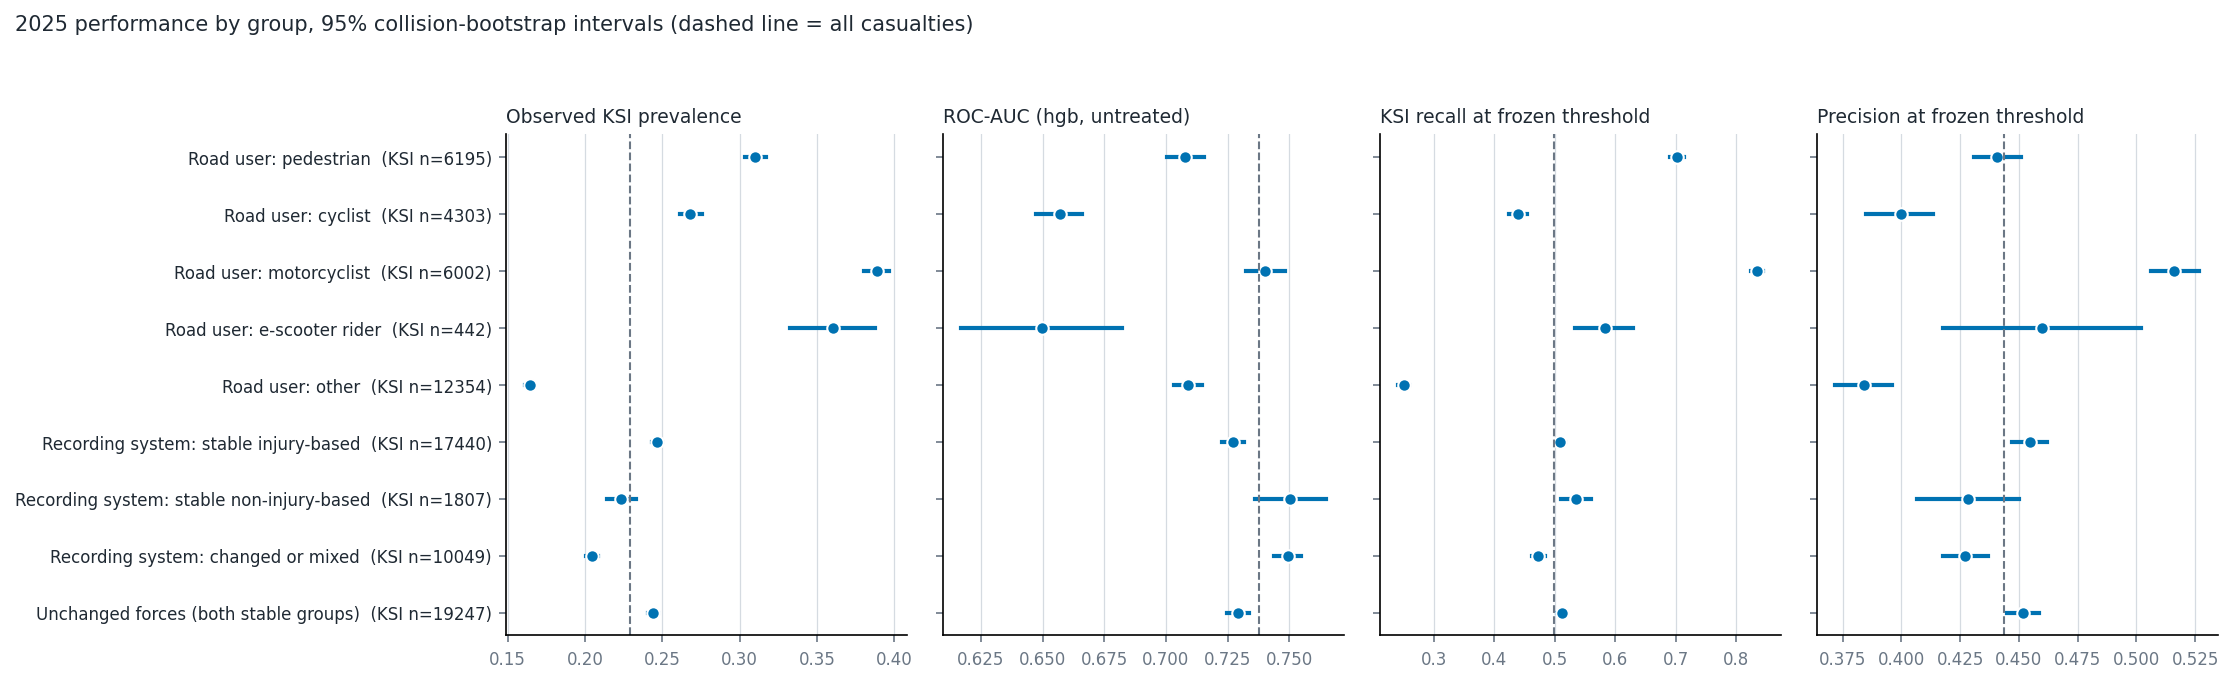

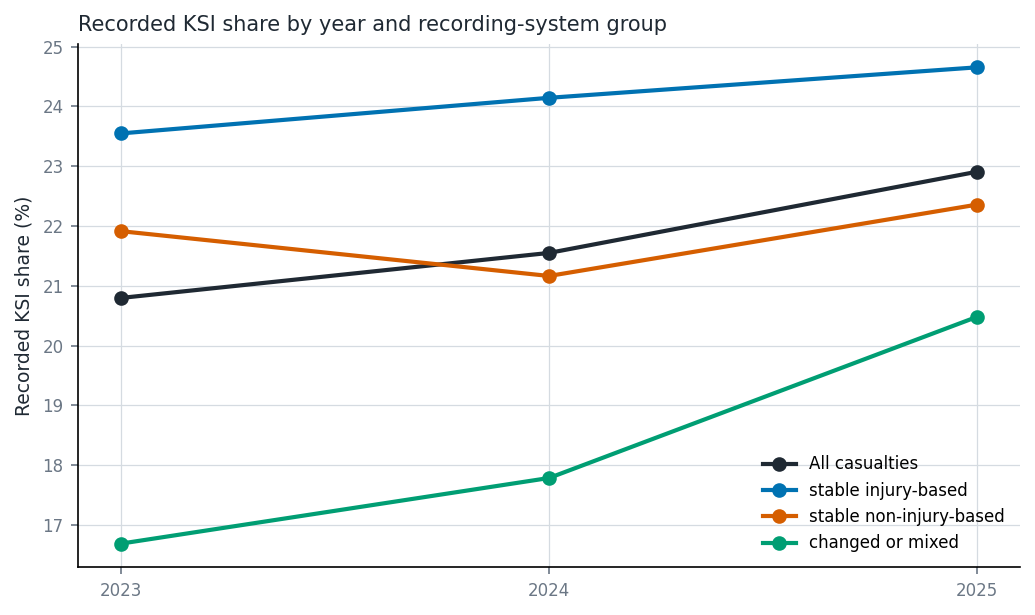

In [9]:
# 9. Figures ----------------------------------------------------------------------------------------------------------
INK, GRID_C, MUTED, BLUE, ORANGE = '#1f2933', '#d5dbe1', '#6b7785', '#0072B2', '#D55E00'
def clean(ax):
    for s in ('top', 'right'): ax.spines[s].set_visible(False)
    ax.grid(color=GRID_C, lw=0.6, axis='x'); ax.set_axisbelow(True); ax.tick_params(labelsize=8, colors=MUTED)

order = [g for g in G if g != ALL]
ylab = [f'{g}  (KSI n={int(ov.set_index("group").loc[g, "ksi_cases"])})' for g in order]
panels = [('Observed KSI prevalence', lambda g: (POINT[f'{g}|prevalence'],) + tuple(interval(f'{g}|prevalence')[0])),
          ('ROC-AUC (hgb, untreated)', lambda g: (POINT[f'{g}|hgb__untreated|auc'],) + tuple(interval(f'{g}|hgb__untreated|auc')[0])),
          ('KSI recall at frozen threshold', lambda g: (POINT[f'{g}|hgb__untreated__opt|recall'],) + tuple(interval(f'{g}|hgb__untreated__opt|recall')[0])),
          ('Precision at frozen threshold', lambda g: (POINT[f'{g}|hgb__untreated__opt|precision'],) + tuple(interval(f'{g}|hgb__untreated__opt|precision')[0]))]
fig, axes = plt.subplots(1, 4, figsize=(15, 4.6), dpi=150, sharey=True)
for ax, (title, fn) in zip(axes, panels):
    vals = [fn(g) for g in order]; yy = np.arange(len(order))[::-1]
    for yi, (e, lo, hi), g in zip(yy, vals, order):
        col = ORANGE if int(ov.set_index('group').loc[g, 'ksi_cases']) < 30 else BLUE
        ax.plot([lo, hi], [yi, yi], color=col, lw=2); ax.plot(e, yi, 'o', color=col, ms=6, mec='white', mew=1)
    ax.axvline(fn(ALL)[0], color=MUTED, ls='--', lw=1)
    ax.set_title(title, fontsize=9, color=INK, loc='left'); clean(ax)
axes[0].set_yticks(np.arange(len(order))[::-1]); axes[0].set_yticklabels(ylab, fontsize=8, color=INK)
fig.suptitle('2025 performance by group, 95% collision-bootstrap intervals (dashed line = all casualties)', fontsize=10, color=INK, x=0.01, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.94)); fig.savefig(RES / 'subgroups_2025_forest.png', facecolor='white'); plt.show()

fig, ax = plt.subplots(figsize=(7, 4.2), dpi=150)
for name, col in zip([ALL] + [f'Recording system: {s}' for s in SYS], [INK, BLUE, ORANGE, '#009E73']):
    s_ = prev_year[prev_year.group == name]; ax.plot(s_['year'], s_['prevalence'] * 100, marker='o', lw=2, color=col, label=name.replace('Recording system: ', ''))
ax.set_xticks(YEARS); ax.set_ylabel('Recorded KSI share (%)', fontsize=9, color=INK); ax.legend(fontsize=8, frameon=False); clean(ax); ax.grid(axis='y', color=GRID_C, lw=0.6)
ax.set_title('Recorded KSI share by year and recording-system group', fontsize=10, color=INK, loc='left')
fig.tight_layout(); fig.savefig(RES / 'ksi_share_by_year_system_group.png', facecolor='white'); plt.show()

In [10]:
# 10. Record what was done -------------------------------------------------------------------------------------------------
files = sorted(p.name for p in RES.glob('*') if p.name.startswith(('subgroups_', 'bootstrap_draws_subgroups', 'ksi_', 'ranking_', 'treated_vs', 'recorded_vs')))
summary = dict(finished=dt.datetime.now().isoformat(timespec='seconds'), notebook='07', bootstrap_replicates=BOOT_REPS, bootstrap_seed=BOOT_SEED,
               refits=False, eval_module_sha256=sha(CODE / 'stats19_eval.py'), labels_sha256=s06['labels_sha256'], scores_sha256=rec['scores_2025']['sha256'],
               groups=list(G), low_ksi_groups=[g for g in G if int(y[GROUPS[g]].sum()) < 30], adjusted_section_run=bool(adj_ok), outputs=files,
               output_sha256={f: sha(RES / f) for f in files if not f.startswith('bootstrap_draws')})
(RES / 'results_2025_notebook07_summary.json').write_text(json.dumps(summary, indent=1))
print(json.dumps({k: v for k, v in summary.items() if k != 'output_sha256'}, indent=1))
print('\nNEXT: notebook 08 refits the models for the shorter 2023 to 2024 comparison and the two sensitivity analyses.')

{
 "finished": "2026-11-07T19:22:29",
 "notebook": "07",
 "bootstrap_replicates": 2000,
 "bootstrap_seed": 20261110,
 "refits": false,
 "eval_module_sha256": "f3418de16c7259ff39b368fad2760257a1adde2e5cc53bfd7f1989b9815f9f87",
 "labels_sha256": "22ddae8fde110307daf9bd711a84f0b9cd18166d24e52194082b60e53cc3d4e3",
 "scores_sha256": "010c53a0a7f95b360989326b7e539e085676f7acc730da3e39ac823d38a65e10",
 "groups": [
  "All casualties",
  "Road user: pedestrian",
  "Road user: cyclist",
  "Road user: motorcyclist",
  "Road user: e-scooter rider",
  "Road user: other",
  "Recording system: stable injury-based",
  "Recording system: stable non-injury-based",
  "Recording system: changed or mixed",
  "Unchanged forces (both stable groups)"
 ],
 "low_ksi_groups": [],
 "adjusted_section_run": true,
 "outputs": [
  "bootstrap_draws_subgroups_2025.parquet",
  "ksi_change_decomposition_2025_vs_2023_24.csv",
  "ksi_prevalence_by_year_and_group.csv",
  "ksi_prevalence_change_2025_vs_2023_24.csv",
  "ksi_s